# EJECT! -- Ballistic Trajectory Simulation for Volcanic Eruptions

This notebook demonstrates the use of the ballistic trajectory simulation code, which calculates the paths of projectiles ejected during volcanic eruptions.

### References

If you use this work, please cite the original sources: 

Original Visual Basic implementation:
  Mastin, L.G. (2001). A simple calculator of ballistic trajectories for blocks ejected during volcanic eruptions.
  U.S. Geological Survey Open-File Report 01-45, 16p.
  https://pubs.usgs.gov/of/2001/0045/

MATLAB translation:
  Strehlow, K., Mastin, L.G., Sandri, L., Gottsmann, J.H., Kilgour, G., Rust, A.C., & Tonini, R. (2019).
  Eject! for Matlab. https://vhub.org/resources/4543



### Overview

The simulation accounts for:
- Atmospheric conditions (pressure, density, temperature)
- Drag forces varying with Mach number
- Wind effects
- Gravity and buoyancy
- Topographic constraints

### Required installed libraries for this workflow

In [19]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from eject import eject

# Set up matplotlib for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

# Increase default figure size
plt.rcParams['figure.figsize'] = (12, 7)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


## Example 1: Single Trajectory Calculation

Let's calculate a single ballistic trajectory with the following parameters:
- **Ejection angle**: 45°
- **Initial velocity**: 100 m/s
- **Projectile diameter**: 0.5 m (50 cm)

In [20]:
# Define input parameters
thetadeg = 45.0  # ejection angle in degrees
vi = 100.0       # initial velocity in m/s
diam = 0.5       # diameter in meters

print(f"Input parameters:")
print(f"  Ejection angle: {thetadeg}°")
print(f"  Initial velocity: {vi} m/s")
print(f"  Diameter: {diam} m")
print()

# Calculate trajectory
print("Calculating trajectory...")
traj = eject(thetadeg, vi, diam)

# Extract coordinates
x_coords = traj[:, 0]
z_coords = traj[:, 1]

# Display results
print(f"\nResults:")
print(f"  Maximum horizontal distance: {x_coords[-1]:.2f} m")
print(f"  Maximum height: {np.max(z_coords):.2f} m")
print(f"  Number of trajectory points: {len(x_coords)}")
print(f"  Final landing height: {z_coords[-1]:.2f} m (landing plane)")

Input parameters:
  Ejection angle: 45.0°
  Initial velocity: 100.0 m/s
  Diameter: 0.5 m

Calculating trajectory...

Results:
  Maximum horizontal distance: 1220.85 m
  Maximum height: 227.74 m
  Number of trajectory points: 524
  Final landing height: -1000.00 m (landing plane)


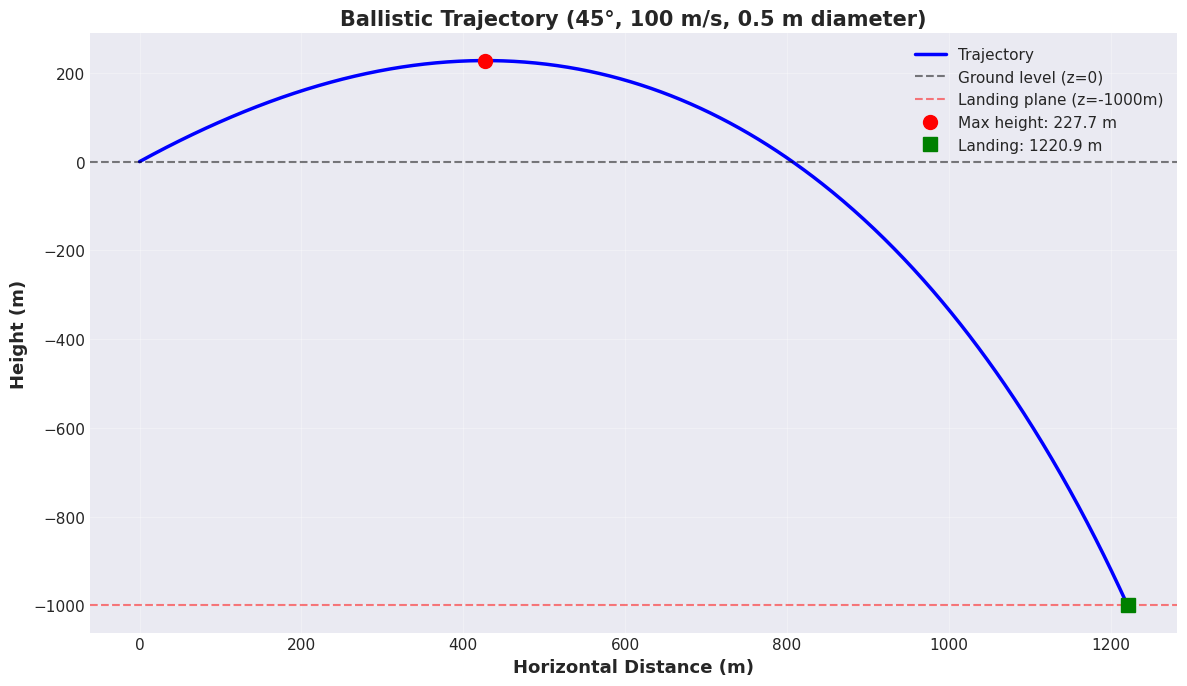


✓ Single trajectory plot complete!


In [21]:
# Plot the trajectory
plt.figure(figsize=(12, 7))
plt.plot(x_coords, z_coords, 'b-', linewidth=2.5, label='Trajectory')
plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Ballistic Trajectory (45°, 100 m/s, 0.5 m diameter)', fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level (z=0)')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane (z=-1000m)')

# Mark maximum height
max_height_idx = np.argmax(z_coords)
plt.plot(x_coords[max_height_idx], z_coords[max_height_idx], 'ro', markersize=10, 
         label=f'Max height: {np.max(z_coords):.1f} m')

# Mark landing point
plt.plot(x_coords[-1], z_coords[-1], 'gs', markersize=10, 
         label=f'Landing: {x_coords[-1]:.1f} m')

plt.legend(fontsize=11, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Single trajectory plot complete!")

## Example 2: Effect of Ejection Angle

Now let's explore how the ejection angle affects the trajectory. We'll compare three different angles:
- 30° (low angle)
- 45° (optimal for distance in vacuum)
- 60° (high angle)

All with the same initial velocity (100 m/s) and diameter (0.5 m).

In [22]:
# Define angles to test
angles = [30, 45, 60]
vi = 100.0
diam = 0.5

# Store results
trajectories = {}
max_distances = {}
max_heights = {}

print("Calculating trajectories for different angles...\n")

for angle in angles:
    print(f"Processing {angle}°...")
    traj = eject(angle, vi, diam)
    trajectories[angle] = traj
    max_distances[angle] = traj[-1, 0]
    max_heights[angle] = np.max(traj[:, 1])
    print(f"  Max distance: {max_distances[angle]:.2f} m")
    print(f"  Max height: {max_heights[angle]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different angles...

Processing 30°...
  Max distance: 1330.58 m
  Max height: 117.83 m

Processing 45°...
  Max distance: 1220.85 m
  Max height: 227.74 m

Processing 60°...
  Max distance: 956.31 m
  Max height: 335.36 m

✓ All trajectories calculated!


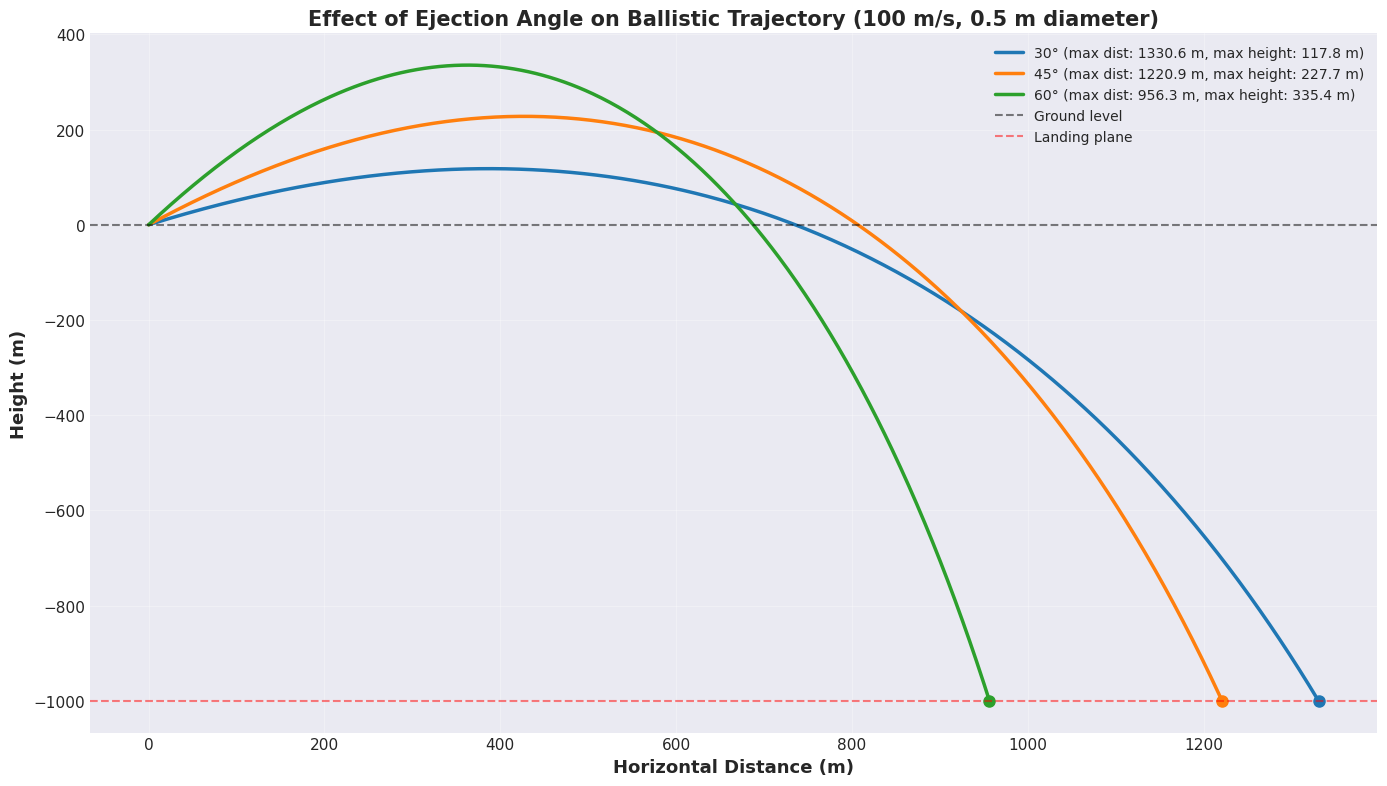


✓ Angle comparison plot complete!


In [23]:
# Plot comparison
plt.figure(figsize=(14, 8))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, orange, green

for idx, angle in enumerate(angles):
    traj = trajectories[angle]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=colors[idx],
             label=f'{angle}° (max dist: {max_distances[angle]:.1f} m, max height: {max_heights[angle]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Ejection Angle on Ballistic Trajectory (100 m/s, 0.5 m diameter)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Angle comparison plot complete!")

### Analysis: Angle Effects

From the results above, we can observe:
- **30° angle** achieves the longest horizontal distance but lower maximum height
- **45° angle** provides a good balance (though not optimal due to drag)
- **60° angle** reaches the highest altitude but travels the shortest horizontal distance

Note that in real atmospheric conditions with drag, the optimal angle for maximum distance is typically less than 45°.

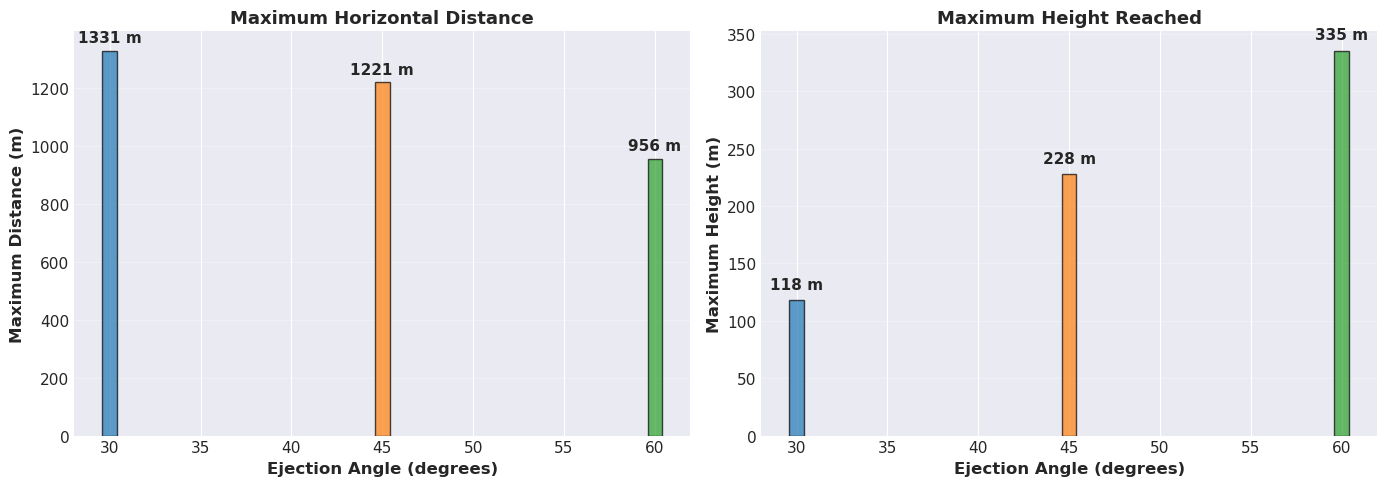


✓ Summary bar charts complete!


In [24]:
# Create a summary bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances
ax1.bar(angles, [max_distances[a] for a in angles], color=colors, alpha=0.7, edgecolor='black')
ax1.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Maximum Horizontal Distance', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')
for i, angle in enumerate(angles):
    ax1.text(angle, max_distances[angle] + 30, f'{max_distances[angle]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights
ax2.bar(angles, [max_heights[a] for a in angles], color=colors, alpha=0.7, edgecolor='black')
ax2.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Maximum Height Reached', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
for i, angle in enumerate(angles):
    ax2.text(angle, max_heights[angle] + 10, f'{max_heights[angle]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Summary bar charts complete!")

## Example 3: Effect of Initial Velocity

Let's examine how the initial velocity affects the trajectory. We'll use a fixed angle of 45° and vary the velocity.

In [25]:
# Define velocities to test
velocities = [50, 75, 100, 125]
angle = 45.0
diam = 0.5

# Store results
vel_trajectories = {}
vel_max_distances = {}
vel_max_heights = {}

print("Calculating trajectories for different initial velocities...\n")

for vel in velocities:
    print(f"Processing {vel} m/s...")
    traj = eject(angle, vel, diam)
    vel_trajectories[vel] = traj
    vel_max_distances[vel] = traj[-1, 0]
    vel_max_heights[vel] = np.max(traj[:, 1])
    print(f"  Max distance: {vel_max_distances[vel]:.2f} m")
    print(f"  Max height: {vel_max_heights[vel]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different initial velocities...

Processing 50 m/s...
  Max distance: 575.28 m
  Max height: 63.14 m

Processing 75 m/s...
  Max distance: 899.67 m
  Max height: 136.38 m

Processing 100 m/s...
  Max distance: 1220.85 m
  Max height: 227.74 m

Processing 125 m/s...
  Max distance: 1525.96 m
  Max height: 330.08 m

✓ All trajectories calculated!


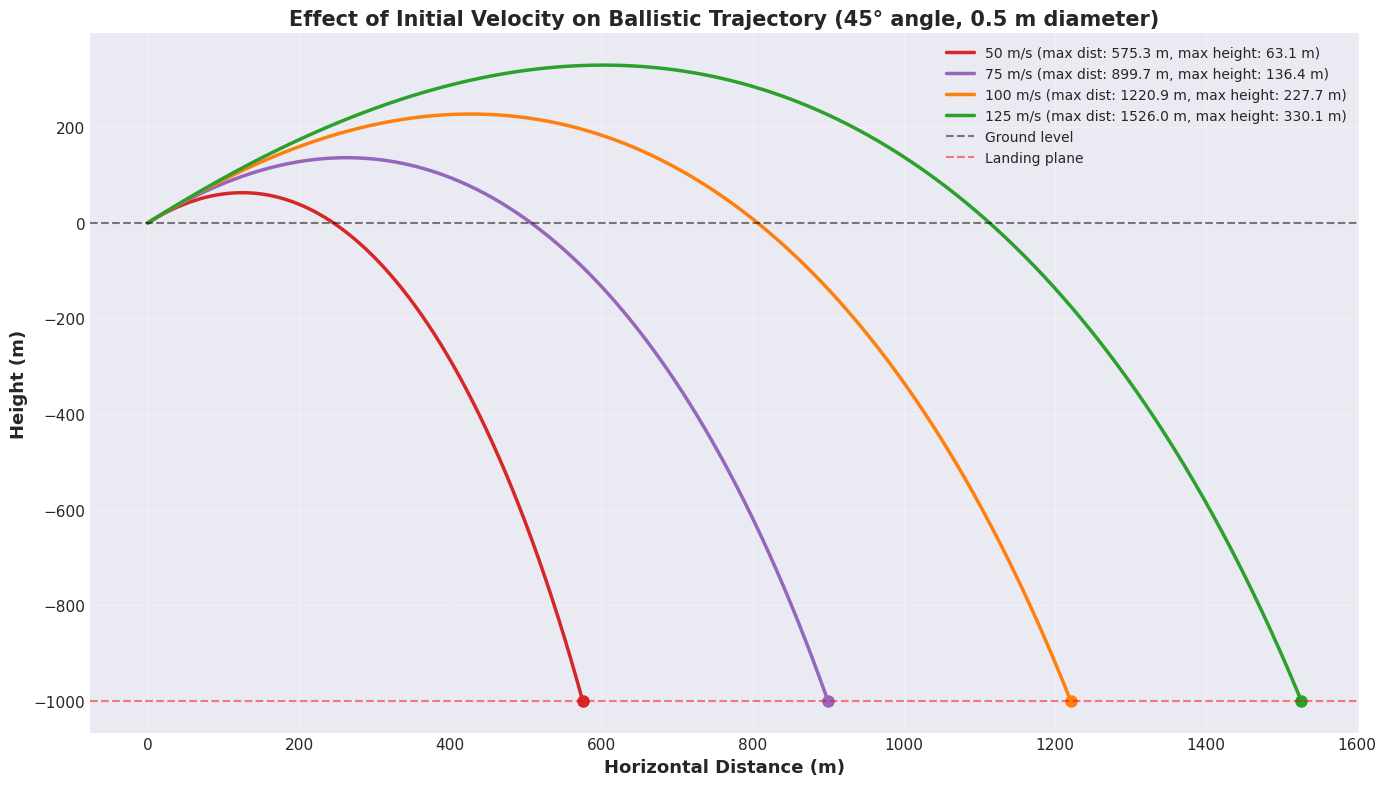


✓ Velocity comparison plot complete!


In [26]:
# Plot comparison
plt.figure(figsize=(14, 8))

vel_colors = ['#d62728', '#9467bd', '#ff7f0e', '#2ca02c']  # Red, purple, orange, green

for idx, vel in enumerate(velocities):
    traj = vel_trajectories[vel]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=vel_colors[idx],
             label=f'{vel} m/s (max dist: {vel_max_distances[vel]:.1f} m, max height: {vel_max_heights[vel]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=vel_colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Initial Velocity on Ballistic Trajectory (45° angle, 0.5 m diameter)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Velocity comparison plot complete!")

### Analysis: Velocity Effects

As expected, higher initial velocities result in:
- Greater horizontal distances
- Higher maximum altitudes
- Longer flight times

The relationship is roughly quadratic - doubling the velocity approximately quadruples the range (in the absence of drag).

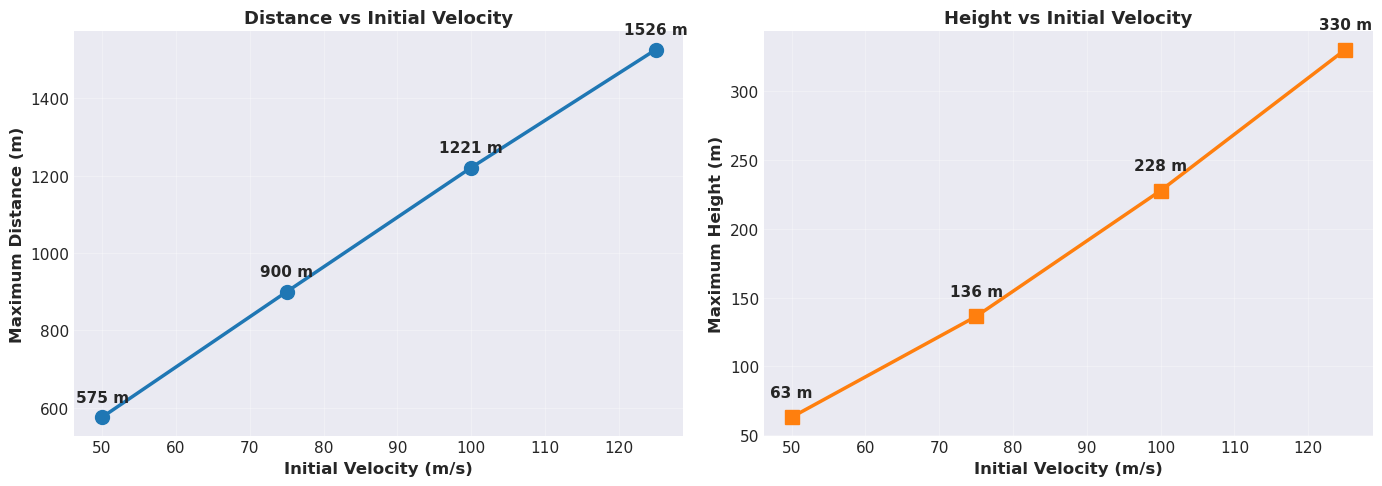


✓ Velocity scaling plots complete!


In [27]:
# Create a summary visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances vs velocity
ax1.plot(velocities, [vel_max_distances[v] for v in velocities], 'o-', 
         linewidth=2.5, markersize=10, color='#1f77b4')
ax1.set_xlabel('Initial Velocity (m/s)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Distance vs Initial Velocity', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
for vel in velocities:
    ax1.text(vel, vel_max_distances[vel] + 40, f'{vel_max_distances[vel]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights vs velocity
ax2.plot(velocities, [vel_max_heights[v] for v in velocities], 's-', 
         linewidth=2.5, markersize=10, color='#ff7f0e')
ax2.set_xlabel('Initial Velocity (m/s)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Height vs Initial Velocity', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
for vel in velocities:
    ax2.text(vel, vel_max_heights[vel] + 15, f'{vel_max_heights[vel]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Velocity scaling plots complete!")

## Example 4: Effect of Projectile Size

Finally, let's examine how the diameter of the projectile affects the trajectory. Larger projectiles have:
- Greater mass (proportional to volume: r³)
- Greater cross-sectional area (proportional to r²)
- Different drag-to-mass ratios

We'll compare projectiles of different sizes with the same initial conditions.

In [28]:
# Define diameters to test (in meters)
diameters = [0.2, 0.5, 1.0, 2.0]  # 20 cm, 50 cm, 1 m, 2 m
angle = 45.0
vel = 100.0

# Store results
size_trajectories = {}
size_max_distances = {}
size_max_heights = {}

print("Calculating trajectories for different projectile sizes...\n")

for d in diameters:
    print(f"Processing diameter {d} m ({d*100:.0f} cm)...")
    traj = eject(angle, vel, d)
    size_trajectories[d] = traj
    size_max_distances[d] = traj[-1, 0]
    size_max_heights[d] = np.max(traj[:, 1])
    print(f"  Max distance: {size_max_distances[d]:.2f} m")
    print(f"  Max height: {size_max_heights[d]:.2f} m")
    print()

print("✓ All trajectories calculated!")

Calculating trajectories for different projectile sizes...

Processing diameter 0.2 m (20 cm)...
  Max distance: 896.97 m
  Max height: 200.84 m

Processing diameter 0.5 m (50 cm)...
  Max distance: 1220.85 m
  Max height: 227.74 m

Processing diameter 1.0 m (100 cm)...
  Max distance: 1396.33 m
  Max height: 240.03 m

Processing diameter 2.0 m (200 cm)...
  Max distance: 1507.61 m
  Max height: 247.12 m

✓ All trajectories calculated!


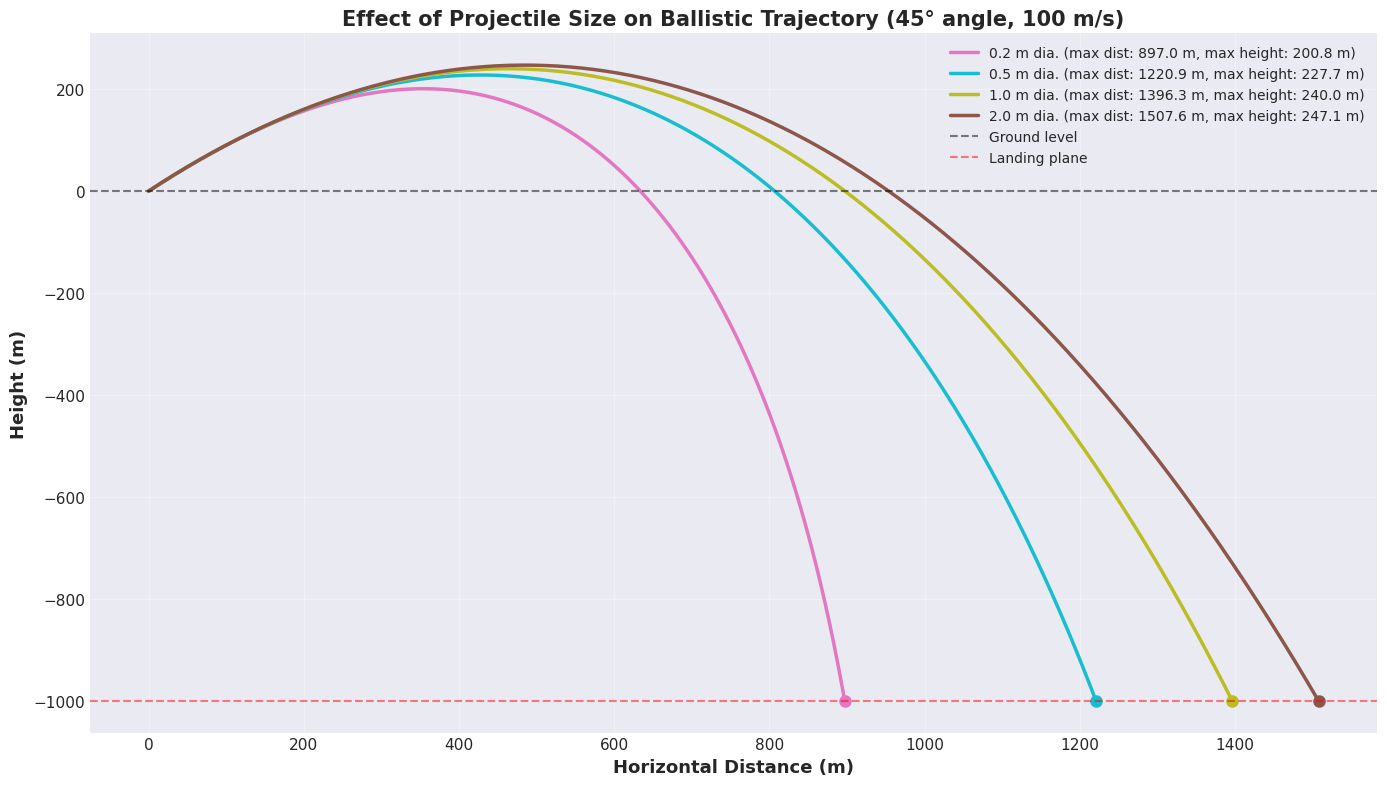


✓ Size comparison plot complete!


In [29]:
# Plot comparison
plt.figure(figsize=(14, 8))

size_colors = ['#e377c2', '#17becf', '#bcbd22', '#8c564b']  # Pink, cyan, yellow-green, brown

for idx, d in enumerate(diameters):
    traj = size_trajectories[d]
    x_coords = traj[:, 0]
    z_coords = traj[:, 1]
    plt.plot(x_coords, z_coords, linewidth=2.5, color=size_colors[idx],
             label=f'{d} m dia. (max dist: {size_max_distances[d]:.1f} m, max height: {size_max_heights[d]:.1f} m)')
    
    # Mark landing points
    plt.plot(x_coords[-1], z_coords[-1], 'o', color=size_colors[idx], markersize=8)

plt.xlabel('Horizontal Distance (m)', fontsize=13, fontweight='bold')
plt.ylabel('Height (m)', fontsize=13, fontweight='bold')
plt.title('Effect of Projectile Size on Ballistic Trajectory (45° angle, 100 m/s)', 
          fontsize=15, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5, label='Ground level')
plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5, label='Landing plane')
plt.legend(fontsize=10, loc='best')
plt.tight_layout()
plt.show()

print("\n✓ Size comparison plot complete!")

### Analysis: Size Effects

Larger projectiles travel farther because:
- Mass increases with volume (r³)
- Drag area increases with cross-section (r²)
- The mass-to-drag ratio increases with size
- Larger projectiles are less affected by atmospheric drag

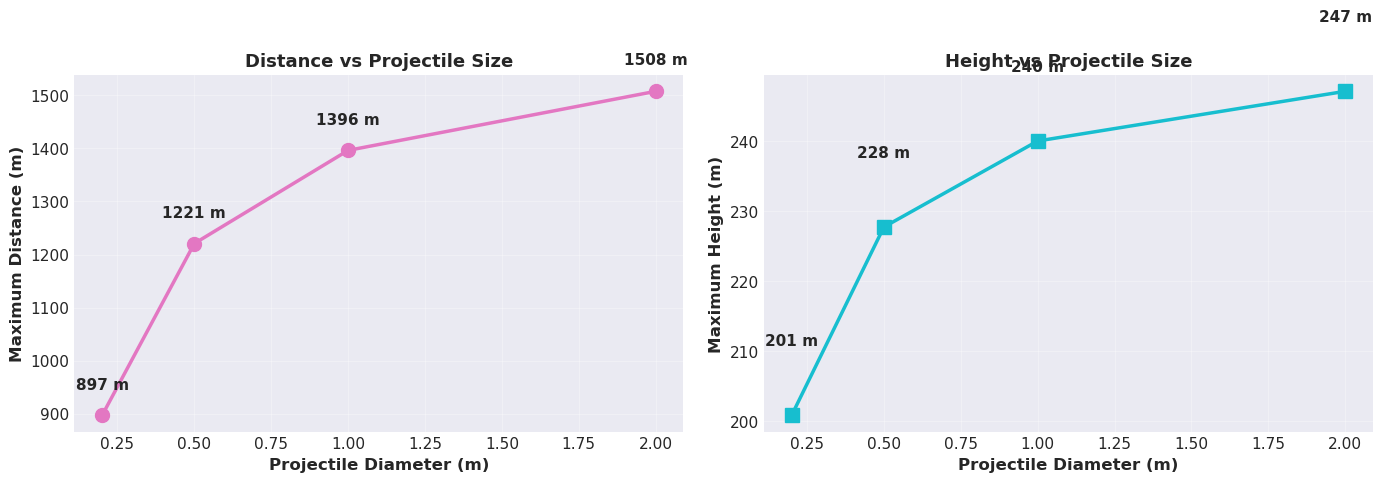


✓ Size scaling plots complete!


In [30]:
# Create comparison charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Maximum distances vs size
ax1.plot(diameters, [size_max_distances[d] for d in diameters], 'o-', 
         linewidth=2.5, markersize=10, color='#e377c2')
ax1.set_xlabel('Projectile Diameter (m)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Maximum Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Distance vs Projectile Size', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
for d in diameters:
    ax1.text(d, size_max_distances[d] + 50, f'{size_max_distances[d]:.0f} m', 
             ha='center', fontweight='bold')

# Maximum heights vs size
ax2.plot(diameters, [size_max_heights[d] for d in diameters], 's-', 
         linewidth=2.5, markersize=10, color='#17becf')
ax2.set_xlabel('Projectile Diameter (m)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Height vs Projectile Size', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)
for d in diameters:
    ax2.text(d, size_max_heights[d] + 10, f'{size_max_heights[d]:.0f} m', 
             ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Size scaling plots complete!")

## Example 5: Interactive Parameter Exploration

Now let's create an interactive widget that allows you to explore how different parameters affect the trajectory in real-time.

**Note:** This requires ipywidgets. If you don't have it installed, you can install it with:
```bash
pip install ipywidgets
```

In [31]:
# Try to import ipywidgets for interactive plots
try:
    from ipywidgets import interact, FloatSlider, IntSlider
    WIDGETS_AVAILABLE = True
    print("✓ ipywidgets available - interactive plot enabled!")
except ImportError:
    WIDGETS_AVAILABLE = False
    print("⚠ ipywidgets not available. Install with: pip install ipywidgets")
    print("Skipping interactive example.")

✓ ipywidgets available - interactive plot enabled!


In [32]:
if WIDGETS_AVAILABLE:
    def plot_interactive_trajectory(angle=45, velocity=100, diameter=0.5):
        """
        Interactive trajectory plotting function.
        """
        # Calculate trajectory
        traj = eject(angle, velocity, diameter)
        x_coords = traj[:, 0]
        z_coords = traj[:, 1]
        
        # Create plot
        plt.figure(figsize=(12, 7))
        plt.plot(x_coords, z_coords, 'b-', linewidth=2.5, label='Trajectory')
        plt.xlabel('Horizontal Distance (m)', fontsize=12, fontweight='bold')
        plt.ylabel('Height (m)', fontsize=12, fontweight='bold')
        plt.title(f'Interactive Ballistic Trajectory\n' + 
                  f'Angle: {angle}°, Velocity: {velocity} m/s, Diameter: {diameter} m',
                  fontsize=13, fontweight='bold')
        plt.grid(True, alpha=0.3)
        plt.axhline(y=0, color='k', linestyle='--', alpha=0.5, linewidth=1.5)
        plt.axhline(y=-1000, color='r', linestyle='--', alpha=0.5, linewidth=1.5)
        
        # Mark key points
        max_height_idx = np.argmax(z_coords)
        plt.plot(x_coords[max_height_idx], z_coords[max_height_idx], 'ro', 
                 markersize=8, label=f'Max height: {np.max(z_coords):.1f} m')
        plt.plot(x_coords[-1], z_coords[-1], 'gs', markersize=8, 
                 label=f'Landing: {x_coords[-1]:.1f} m')
        
        plt.legend(fontsize=10)
        plt.tight_layout()
        plt.show()
    
    # Create interactive widget
    interact(plot_interactive_trajectory,
             angle=IntSlider(min=15, max=75, step=5, value=45, 
                            description='Angle (°):'),
             velocity=IntSlider(min=25, max=500, step=5, value=100, 
                               description='Velocity (m/s):'),
             diameter=FloatSlider(min=0.1, max=3.0, step=0.1, value=0.5, 
                                 description='Diameter (m):'))
else:
    print("Interactive plot not available. Install ipywidgets to enable.")

interactive(children=(IntSlider(value=45, description='Angle (°):', max=75, min=15, step=5), IntSlider(value=1…

In [ ]:
print("\n" + "="*70)
print("  Ballistic Trajectory Simulation - Notebook Complete!")
print("="*70)
print("\nAll examples have been successfully executed.")
print("\nFor more information, see the README.md file.")
print("\n" + "="*70)
print("CITATIONS")
print("="*70)
print("\nOriginal Visual Basic implementation:")
print("  Mastin, L.G. (2001). A simple calculator of ballistic trajectories")
print("  for blocks ejected during volcanic eruptions.")
print("  U.S. Geological Survey Open-File Report 01-45, 16p.")
print("  https://pubs.usgs.gov/of/2001/0045/")
print("\nMATLAB translation:")
print("  Strehlow, K., Mastin, L.G., Sandri, L., Gottsmann, J.H.,")
print("  Kilgour, G., Rust, A.C., & Tonini, R. (2019).")
print("  Eject! for Matlab. https://vhub.org/resources/4543")
print("\nRelated publication:")
print("  Strehlow, K., Sandri, L., Gottsmann, J.H., Kilgour, G.,")
print("  Rust, A.C., & Tonini, R. (2017). Phreatic eruptions at")
print("  crater lakes: occurrence statistics and probabilistic")
print("  hazard forecast. Journal of Applied Volcanology, 6(4).")
print("  DOI: 10.1186/s13617-016-0053-2")
